<a href="https://colab.research.google.com/github/tommystarrrrrrr/2026_Machine_Learning/blob/main/dataset_diabet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset diabet

=== Dataframe Hasil Evaluasi ===
| Model         |   Akurasi |   Presisi |   Recall |   F1-Score |
|:--------------|----------:|----------:|---------:|-----------:|
| KNN           |  0.855769 |  0.951613 | 0.830986 |   0.887218 |
| Decision Tree |  0.951923 |  1        | 0.929577 |   0.963504 |
| Random Forest |  0.990385 |  1        | 0.985915 |   0.992908 |


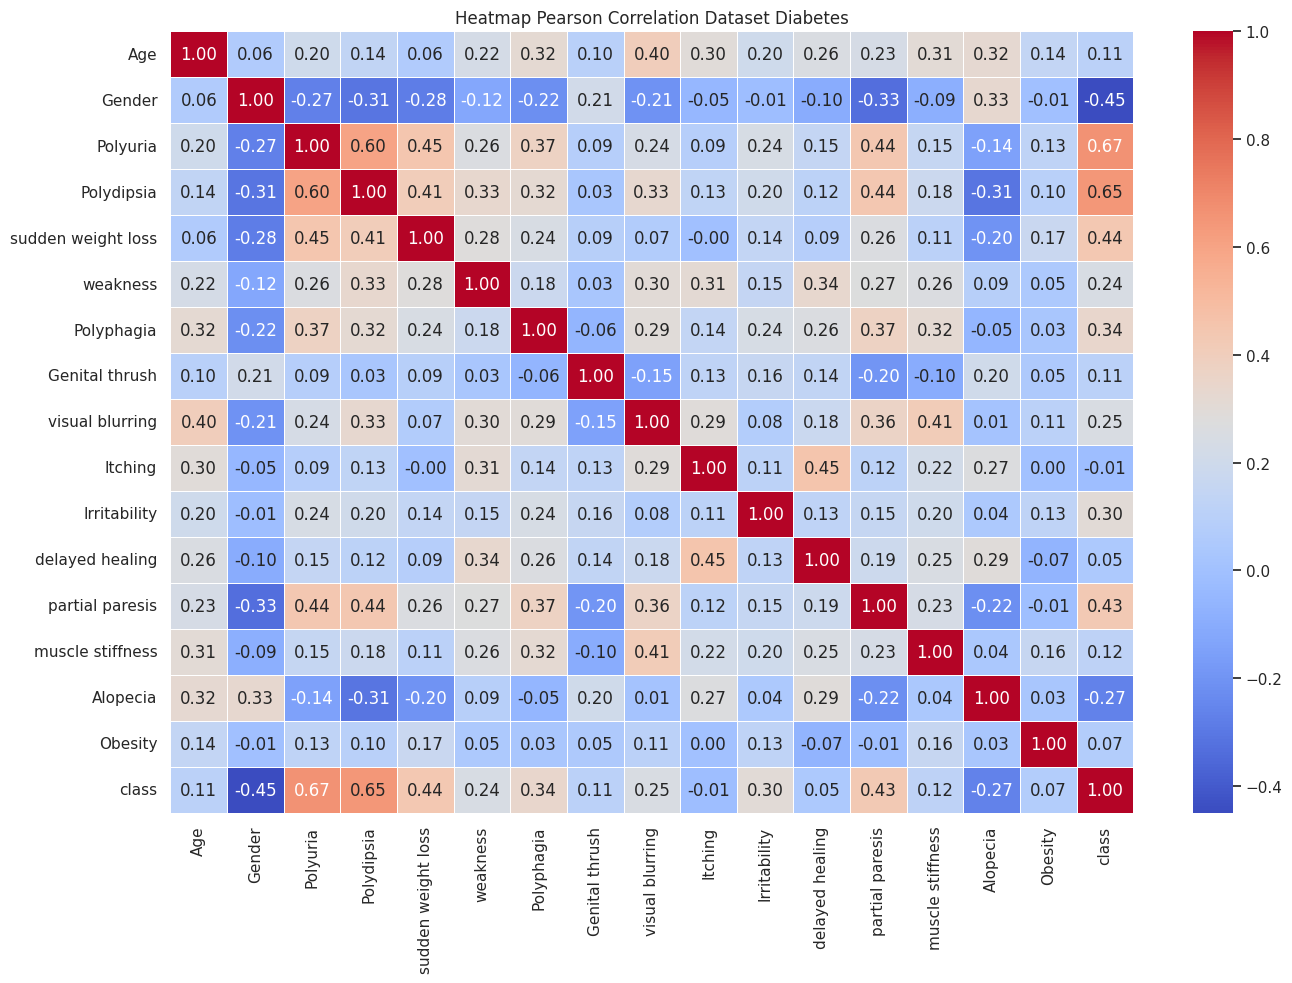

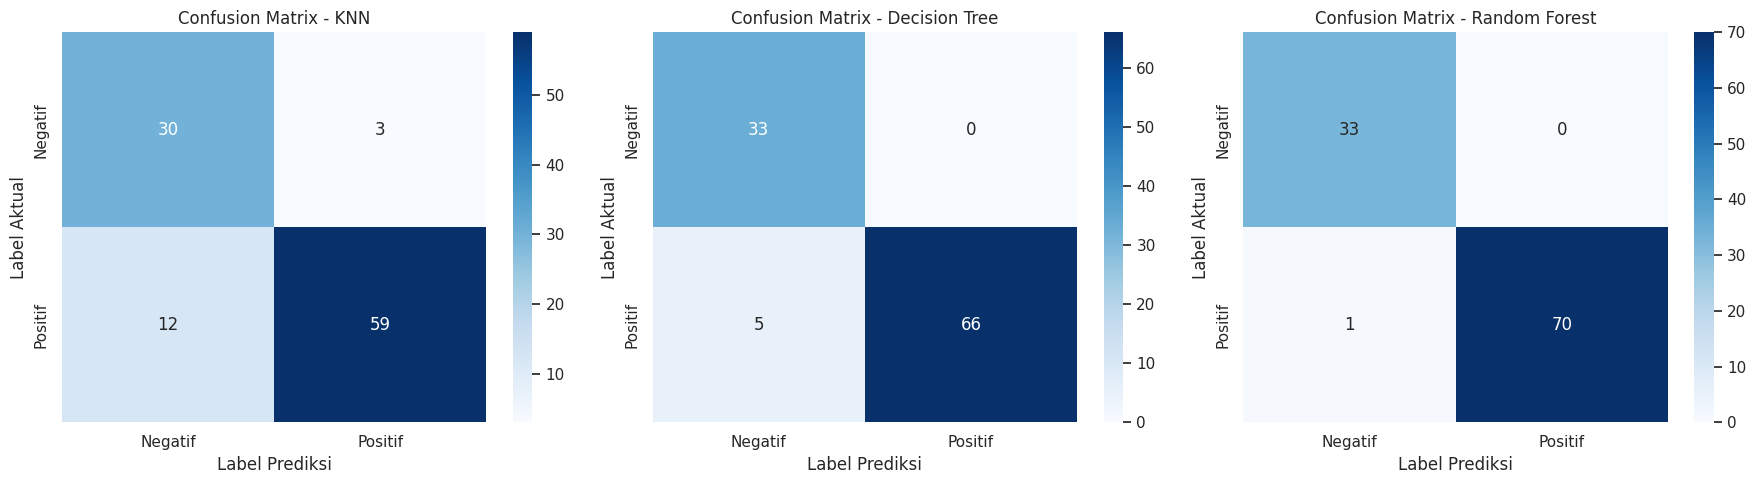

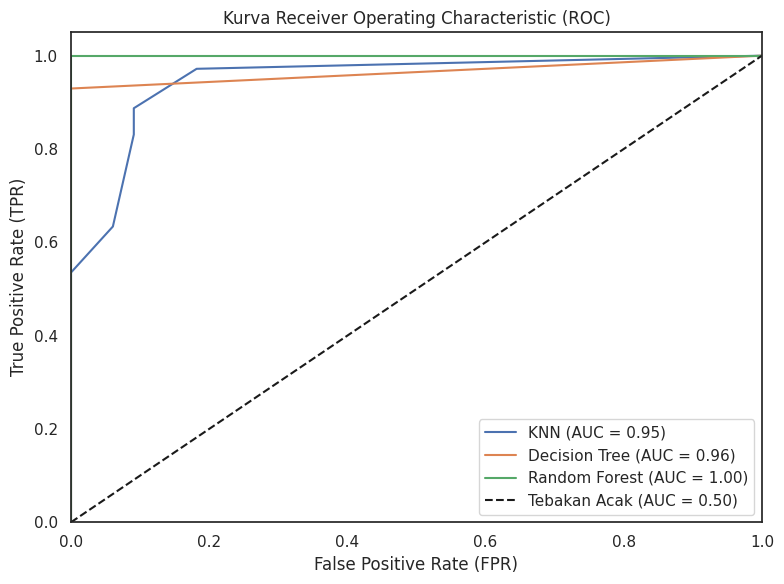

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

# 1. Memuat Dataset
df = pd.read_csv('diabetes_data_upload.csv')

# 2. Pra-pemrosesan Data (Encoding Data Kategorik)
# Mengubah nilai teks (Yes/No, Male/Female, Positive/Negative) menjadi angka
le = LabelEncoder()
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

# 3. Memisahkan Fitur (X) dan Target (y)
X = df.drop('class', axis=1)
y = df['class']

# Membagi data (80% Data Latih, 20% Data Uji)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Inisialisasi Model Klasifikasi
models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42)
}

# 5. Pelatihan dan Pengumpulan Metrik Evaluasi
results = []
cms = {}
roc_data = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    # Menghitung Metrik
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({'Model': name, 'Akurasi': acc, 'Presisi': prec, 'Recall': rec, 'F1-Score': f1})
    cms[name] = confusion_matrix(y_test, y_pred)

    # Menghitung Data Kurva ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)
    roc_data[name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

# Menampilkan DataFrame Evaluasi
results_df = pd.DataFrame(results)
print("=== Dataframe Hasil Evaluasi ===")
print(results_df.to_markdown(index=False))

# 6. Visualisasi
sns.set_theme(style="white")

# a) Heatmap Pearson Correlation
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Heatmap Pearson Correlation Dataset Diabetes')
plt.tight_layout()
plt.show()

# b) Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (name, cm) in enumerate(cms.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Negatif', 'Positif'], yticklabels=['Negatif', 'Positif'])
    axes[i].set_title(f'Confusion Matrix - {name}')
    axes[i].set_xlabel('Label Prediksi')
    axes[i].set_ylabel('Label Aktual')
plt.tight_layout()
plt.show()

# c) Kurva ROC
plt.figure(figsize=(8, 6))
for name, data in roc_data.items():
    plt.plot(data['fpr'], data['tpr'], label=f"{name} (AUC = {data['auc']:.2f})")
plt.plot([0, 1], [0, 1], 'k--', label='Tebakan Acak (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Kurva Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()